# Product-Level Monthly Demand Forecasting

## 1. Project Overview

The objective of this project is to develop a machine learning model that forecasts monthly product demand for every `product_id` using historical sales data.

The forecasting system will use a global machine learning model trained on historical observations from all products rather than training a separate model for each product.

## 2. Forecasting Granularity

**Product × Month**

Each observation represents the total quantity sold for a specific product during a specific month.

**Target Variable:** `gross_quantity_sold`

The target represents the total quantity sold before subtracting returned quantities.

## 3. Business Objectives

- Forecast demand for individual products.
- Support manufacturing and production planning.
- Improve warehouse capacity and inventory planning.
- Identify seasonal demand patterns.
- Support supply chain and resource allocation decisions.
- Provide company-level and quarterly demand forecasts through aggregation.

## 4. Modeling Approach

A global CatBoost Regressor will be investigated as the primary forecasting model.

The model will use:

- Product-related features.
- Calendar and seasonal features.
- Historical demand (lag features).
- Rolling statistical features.
- Relevant business-related features.

## 5. Forecasting Strategy

The project will follow chronological validation to prevent data leakage.

- Training: Historical observations through December 2025.
- Validation: A chronological validation period within the training history.
- Testing: Completed months of 2026.
- Final evaluation: Monthly and quarterly forecasting metrics.

## 6. Future Extensions

- Forecasting demand for the top 10 products.
- Forecasting demand at branch level.
- Combining product forecasts with branch-level demand analysis.
- Using forecast outputs for manufacturing and warehouse optimization.

In [1]:
# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Date and Time
from datetime import datetime

# Machine Learning
from catboost import CatBoostRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Model Evaluation
from sklearn.model_selection import TimeSeriesSplit

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Display Settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

# Visualization Settings
sns.set_theme(style="whitegrid")

print("All libraries imported successfully.")

All libraries imported successfully.


In [7]:
from  pathlib import Path

In [8]:
DATA_DIR = Path("data")

sales_items = pd.read_csv(
    DATA_DIR / "sales_order_items.csv"
)

sales_orders = pd.read_csv(
    DATA_DIR / "sales_orders.csv"
)

products = pd.read_csv(
    DATA_DIR / "products_catalog.csv"
)

branches = pd.read_csv(
    DATA_DIR / "branches.csv"
)

print("All datasets loaded successfully.")

All datasets loaded successfully.


In [ ]:
sales_items["order_date"] = pd.to_datetime(
    sales_items["order_date"],
    errors="raise"
)

sales_orders["order_date"] = pd.to_datetime(
    sales_orders["order_date"],
    errors="raise"
)

branches["opening_date"] = pd.to_datetime(
    branches["opening_date"],
    errors="raise"
)

In [10]:
sales_items["order_date"] = pd.to_datetime(
    sales_items["order_date"],
    errors="raise"
)

sales_orders["order_date"] = pd.to_datetime(
    sales_orders["order_date"],
    errors="raise"
)

branches["opening_date"] = pd.to_datetime(
    branches["opening_date"],
    errors="raise"
)

print("Date columns converted successfully.")

Date columns converted successfully.


In [11]:
status_counts = (
    sales_orders["status"]
    .value_counts(dropna=False)
    .rename_axis("status")
    .reset_index(name="orders_count")
)

status_counts["percentage"] = (
    status_counts["orders_count"]
    / len(sales_orders)
    * 100
)

display(status_counts)

,status,orders_count,percentage
0,Completed,448120,82.99
1,Delivered,81152,15.03
2,Partially returned,10728,1.99


In [12]:
sales_items["month"] = (
    sales_items["order_date"]
    .dt.to_period("M")
)

monthly_product_demand = (
    sales_items
    .groupby(
        ["month", "product_id"],
        as_index=False
    )
    .agg(
        gross_quantity_demanded=("quantity", "sum")
    )
)

monthly_product_demand["month"] = (
    monthly_product_demand["month"]
    .dt.to_timestamp()
)

monthly_product_demand = (
    monthly_product_demand
    .sort_values(["product_id", "month"])
    .reset_index(drop=True)
)

display(monthly_product_demand.head(10))

,month,product_id,gross_quantity_demanded
0,2018-10-01,PR0001,12
1,2018-11-01,PR0001,36
2,2018-12-01,PR0001,77
3,2019-01-01,PR0001,37
4,2019-02-01,PR0001,20
5,2019-03-01,PR0001,64
6,2019-04-01,PR0001,50
7,2019-05-01,PR0001,55
8,2019-06-01,PR0001,34
9,2019-07-01,PR0001,37


In [13]:
# Define the complete monthly date range
all_months = pd.date_range(
    start=monthly_product_demand["month"].min(),
    end=monthly_product_demand["month"].max(),
    freq="MS"
)

# Get all unique products
all_products = products["product_id"].drop_duplicates()

# Create every Product-Month combination
product_month_index = pd.MultiIndex.from_product(
    [all_products, all_months],
    names=["product_id", "month"]
)

# Convert the index into a DataFrame
product_month_grid = product_month_index.to_frame(index=False)

# Merge with actual monthly demand
monthly_product_demand = product_month_grid.merge(
    monthly_product_demand,
    on=["product_id", "month"],
    how="left"
)

# Replace missing demand with zero
monthly_product_demand["gross_quantity_demanded"] = (
    monthly_product_demand["gross_quantity_demanded"]
    .fillna(0)
)

# Sort the dataset
monthly_product_demand = (
    monthly_product_demand
    .sort_values(["product_id", "month"])
    .reset_index(drop=True)
)

display(monthly_product_demand.head(15))

,product_id,month,gross_quantity_demanded
0,PR0001,2018-10-01,12
1,PR0001,2018-11-01,36
2,PR0001,2018-12-01,77
3,PR0001,2019-01-01,37
4,PR0001,2019-02-01,20
5,PR0001,2019-03-01,64
6,PR0001,2019-04-01,50
7,PR0001,2019-05-01,55
8,PR0001,2019-06-01,34
9,PR0001,2019-07-01,37


In [14]:
# Identify the first month with positive demand for each product
first_demand_month = (
    monthly_product_demand[
        monthly_product_demand["gross_quantity_demanded"] > 0
    ]
    .groupby("product_id")["month"]
    .min()
    .rename("first_demand_month")
)

# Attach the first demand month to each observation
monthly_product_demand = monthly_product_demand.merge(
    first_demand_month,
    on="product_id",
    how="left"
)

# Keep observations from the first observed demand month onward
monthly_product_demand = (
    monthly_product_demand[
        monthly_product_demand["month"]
        >= monthly_product_demand["first_demand_month"]
    ]
    .copy()
)

# Remove helper column
monthly_product_demand = (
    monthly_product_demand
    .drop(columns="first_demand_month")
    .sort_values(["product_id", "month"])
    .reset_index(drop=True)
)

print(f"Dataset shape: {monthly_product_demand.shape}")
print(f"Unique products: {monthly_product_demand['product_id'].nunique():,}")

display(monthly_product_demand.head(10))

Dataset shape: (13483, 3)
Unique products: 139


,product_id,month,gross_quantity_demanded
0,PR0001,2018-10-01,12
1,PR0001,2018-11-01,36
2,PR0001,2018-12-01,77
3,PR0001,2019-01-01,37
4,PR0001,2019-02-01,20
5,PR0001,2019-03-01,64
6,PR0001,2019-04-01,50
7,PR0001,2019-05-01,55
8,PR0001,2019-06-01,34
9,PR0001,2019-07-01,37


In [15]:
product_features = products[
    [
        "product_id",
        "category_en",
        "audience",
        "listed_price_EGP"
    ]
].drop_duplicates(subset="product_id")

monthly_product_demand = monthly_product_demand.merge(
    product_features,
    on="product_id",
    how="left",
    validate="many_to_one"
)

monthly_product_demand = (
    monthly_product_demand
    .sort_values(["product_id", "month"])
    .reset_index(drop=True)
)

display(monthly_product_demand.head(10))

,product_id,month,gross_quantity_demanded,category_en,audience,listed_price_EGP
0,PR0001,2018-10-01,12,Socks,Men,290
1,PR0001,2018-11-01,36,Socks,Men,290
2,PR0001,2018-12-01,77,Socks,Men,290
3,PR0001,2019-01-01,37,Socks,Men,290
4,PR0001,2019-02-01,20,Socks,Men,290
5,PR0001,2019-03-01,64,Socks,Men,290
6,PR0001,2019-04-01,50,Socks,Men,290
7,PR0001,2019-05-01,55,Socks,Men,290
8,PR0001,2019-06-01,34,Socks,Men,290
9,PR0001,2019-07-01,37,Socks,Men,290


In [16]:
# Get unique months
all_months = pd.DatetimeIndex(
    monthly_product_demand["month"].unique()
).sort_values()

# Count branches opened on or before the beginning of each month
monthly_branch_count = pd.DataFrame({
    "month": all_months
})

monthly_branch_count["active_branches"] = (
    monthly_branch_count["month"]
    .apply(
        lambda month: (
            branches["opening_date"] <= month
        ).sum()
    )
)

# Merge branch count into product-month dataset
monthly_product_demand = monthly_product_demand.merge(
    monthly_branch_count,
    on="month",
    how="left",
    validate="many_to_one"
)

display(
    monthly_product_demand[
        ["month", "product_id", "gross_quantity_demanded", "active_branches"]
    ].head(15)
)

,month,product_id,gross_quantity_demanded,active_branches
0,2018-10-01,PR0001,12,0
1,2018-11-01,PR0001,36,0
2,2018-12-01,PR0001,77,6
3,2019-01-01,PR0001,37,10
4,2019-02-01,PR0001,20,14
5,2019-03-01,PR0001,64,17
6,2019-04-01,PR0001,50,19
7,2019-05-01,PR0001,55,21
8,2019-06-01,PR0001,34,25
9,2019-07-01,PR0001,37,30


In [17]:
# Aggregate total monthly demand
monthly_company_demand = (
    monthly_product_demand
    .groupby("month", as_index=False)
    .agg(
        total_demand=("gross_quantity_demanded", "sum"),
        active_branches=("active_branches", "first")
    )
)

# Calculate monthly changes
monthly_company_demand["demand_change"] = (
    monthly_company_demand["total_demand"].diff()
)

monthly_company_demand["branches_change"] = (
    monthly_company_demand["active_branches"].diff()
)

# Calculate correlation
correlation = monthly_company_demand[
    ["total_demand", "active_branches"]
].corr().iloc[0, 1]

print(f"Correlation between active branches and total demand: {correlation:.3f}")

display(monthly_company_demand.head(15))

Correlation between active branches and total demand: 0.553


,month,total_demand,active_branches,demand_change,branches_change
0,2018-10-01,7611,0,NaN,NaN
1,2018-11-01,22492,0,"14,881.00",0.00
2,2018-12-01,24490,6,"1,998.00",6.00
3,2019-01-01,21133,10,"-3,357.00",4.00
4,2019-02-01,19254,14,"-1,879.00",4.00
5,2019-03-01,24735,17,"5,481.00",3.00
6,2019-04-01,23895,19,-840.00,2.00
7,2019-05-01,25360,21,"1,465.00",2.00
8,2019-06-01,20847,25,"-4,513.00",4.00
9,2019-07-01,20459,30,-388.00,5.00


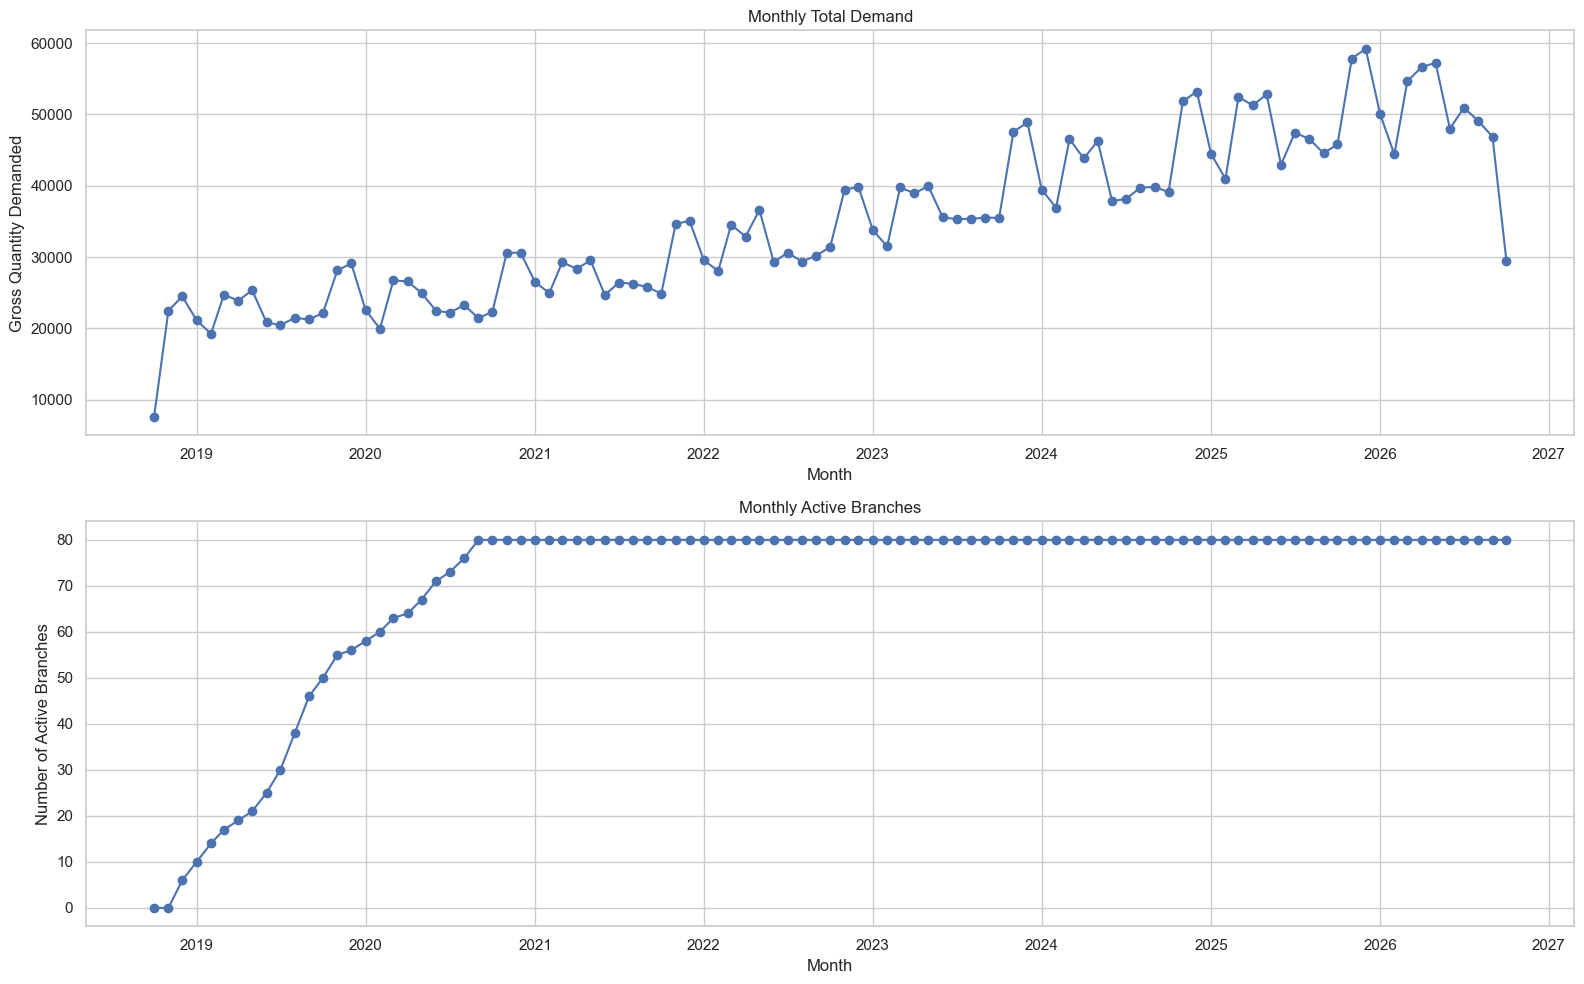

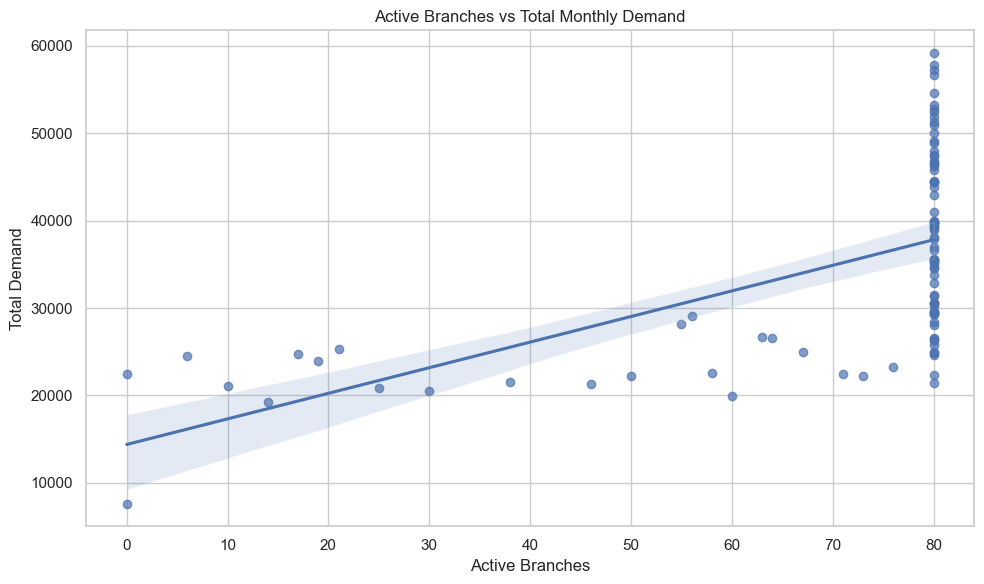

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Monthly total demand
axes[0].plot(
    monthly_company_demand["month"],
    monthly_company_demand["total_demand"],
    marker="o"
)

axes[0].set_title("Monthly Total Demand")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Gross Quantity Demanded")
axes[0].grid(True)

# Monthly active branches
axes[1].plot(
    monthly_company_demand["month"],
    monthly_company_demand["active_branches"],
    marker="o"
)

axes[1].set_title("Monthly Active Branches")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Number of Active Branches")
axes[1].grid(True)

plt.tight_layout()
plt.show()


# Relationship between active branches and total demand
plt.figure(figsize=(10, 6))

sns.regplot(
    data=monthly_company_demand,
    x="active_branches",
    y="total_demand",
    scatter_kws={"alpha": 0.7}
)

plt.title("Active Branches vs Total Monthly Demand")
plt.xlabel("Active Branches")
plt.ylabel("Total Demand")
plt.tight_layout()
plt.show()

In [19]:
product_demand_summary = (
    monthly_product_demand
    .groupby("product_id")
    .agg(
        total_demand=("gross_quantity_demanded", "sum"),
        average_monthly_demand=("gross_quantity_demanded", "mean"),
        median_monthly_demand=("gross_quantity_demanded", "median"),
        std_monthly_demand=("gross_quantity_demanded", "std"),
        active_months=("gross_quantity_demanded", lambda x: (x > 0).sum()),
        zero_demand_months=("gross_quantity_demanded", lambda x: (x == 0).sum())
    )
    .reset_index()
    .sort_values("total_demand", ascending=False)
)

display(product_demand_summary.head(20))

print(f"Total products: {product_demand_summary['product_id'].nunique():,}")
print(f"Total monthly observations: {len(monthly_product_demand):,}")

,product_id,total_demand,average_monthly_demand,median_monthly_demand,std_monthly_demand,active_months,zero_demand_months
59,PR0060,56136,578.72,555.00,204.14,97,0
81,PR0082,55324,570.35,531.00,198.62,97,0
119,PR0120,55278,569.88,545.00,206.70,97,0
85,PR0086,54716,564.08,528.00,184.38,97,0
133,PR0134,54122,557.96,548.00,201.47,97,0
89,PR0090,53586,552.43,533.00,192.84,97,0
84,PR0085,52657,542.86,530.00,171.42,97,0
137,PR0138,50602,521.67,514.00,186.40,97,0
94,PR0095,50106,516.56,467.00,192.04,97,0
80,PR0081,49911,514.55,472.00,183.87,97,0


Total products: 139
Total monthly observations: 13,483


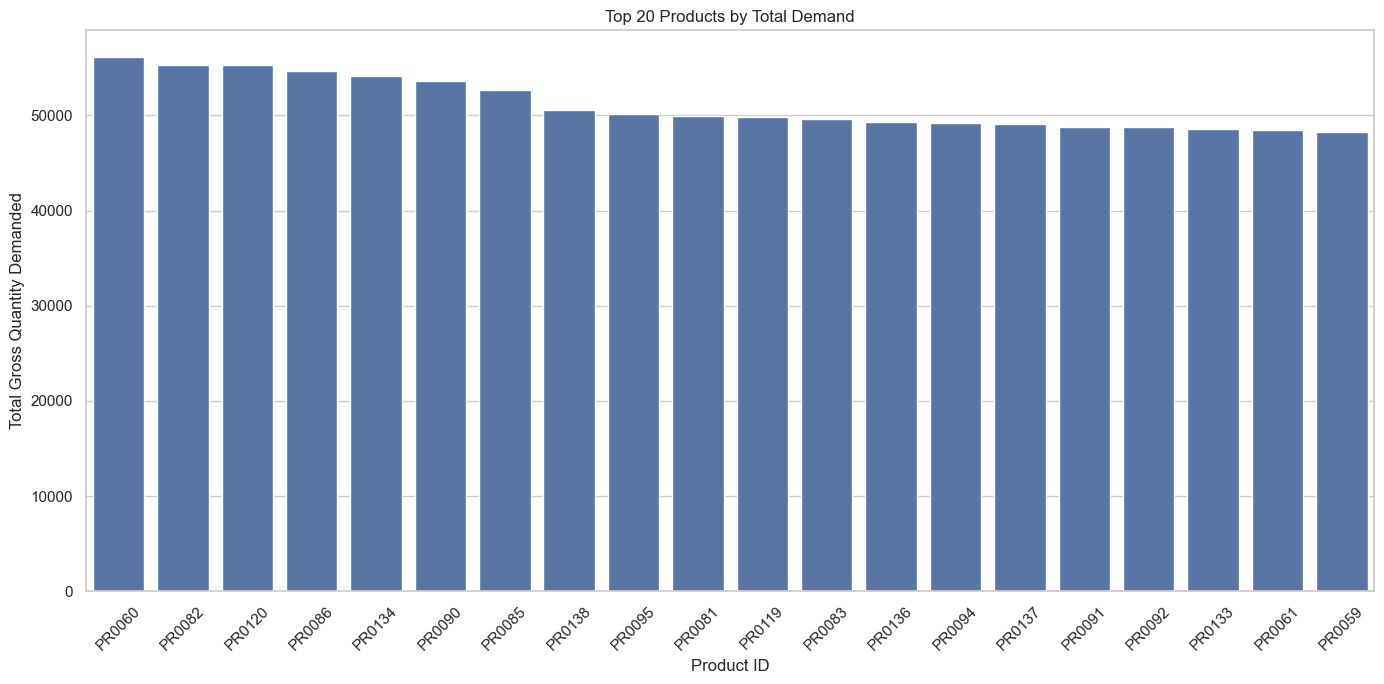

In [20]:
top_20_products = product_demand_summary.head(20)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=top_20_products,
    x="product_id",
    y="total_demand"
)

plt.title("Top 20 Products by Total Demand")
plt.xlabel("Product ID")
plt.ylabel("Total Gross Quantity Demanded")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

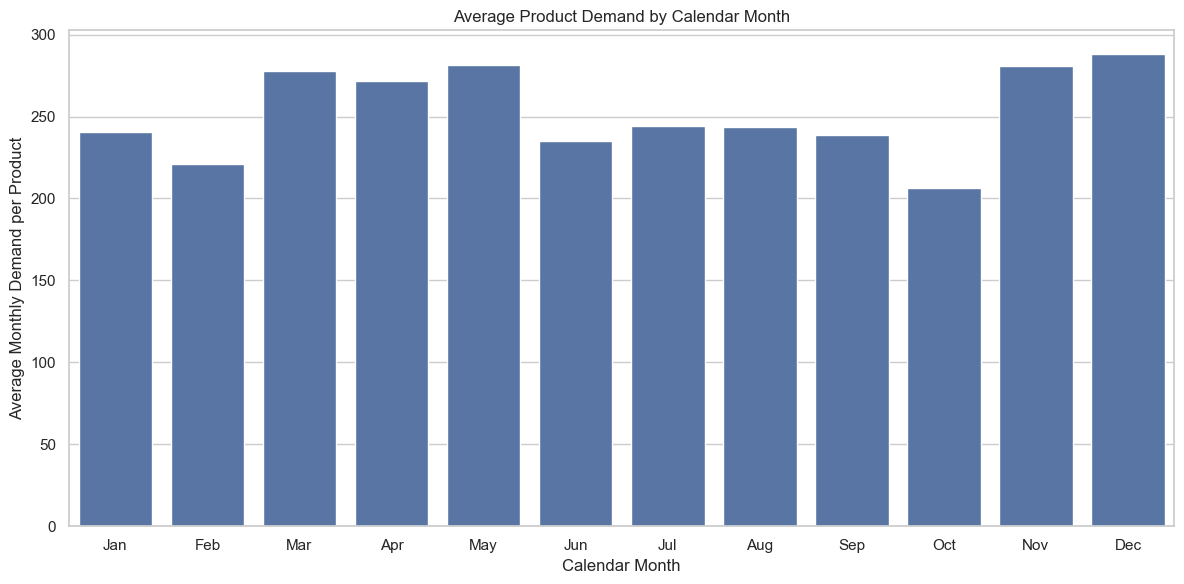

,month_number,average_demand,total_demand
0,1,240.66,267611
1,2,221.20,245978
2,3,277.61,308698
3,4,271.93,302384
4,5,281.26,312766
5,6,235.33,261684
6,7,244.18,271530
7,8,243.88,271194
8,9,238.74,265483
9,10,206.52,258360


In [21]:
# Extract calendar month
monthly_product_demand["month_number"] = (
    monthly_product_demand["month"].dt.month
)

# Aggregate demand by calendar month
seasonal_demand = (
    monthly_product_demand
    .groupby("month_number", as_index=False)
    .agg(
        average_demand=("gross_quantity_demanded", "mean"),
        total_demand=("gross_quantity_demanded", "sum")
    )
)

# Plot average monthly demand
plt.figure(figsize=(12, 6))

sns.barplot(
    data=seasonal_demand,
    x="month_number",
    y="average_demand"
)

plt.title("Average Product Demand by Calendar Month")
plt.xlabel("Calendar Month")
plt.ylabel("Average Monthly Demand per Product")
plt.xticks(
    ticks=range(12),
    labels=[
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ]
)

plt.tight_layout()
plt.show()

display(seasonal_demand)

,year,total_demand,average_monthly_demand,observed_months,average_active_branches
0,2018,54593,"18,197.67",3,2.00
1,2019,277858,"23,154.83",12,31.75
2,2020,293811,"24,484.25",12,71.00
3,2021,336439,"28,036.58",12,80.00
4,2022,391843,"32,653.58",12,80.00
5,2023,457698,"38,141.50",12,80.00
6,2024,512715,"42,726.25",12,80.00
7,2025,586290,"48,857.50",12,80.00
8,2026,487408,"48,740.80",10,80.00


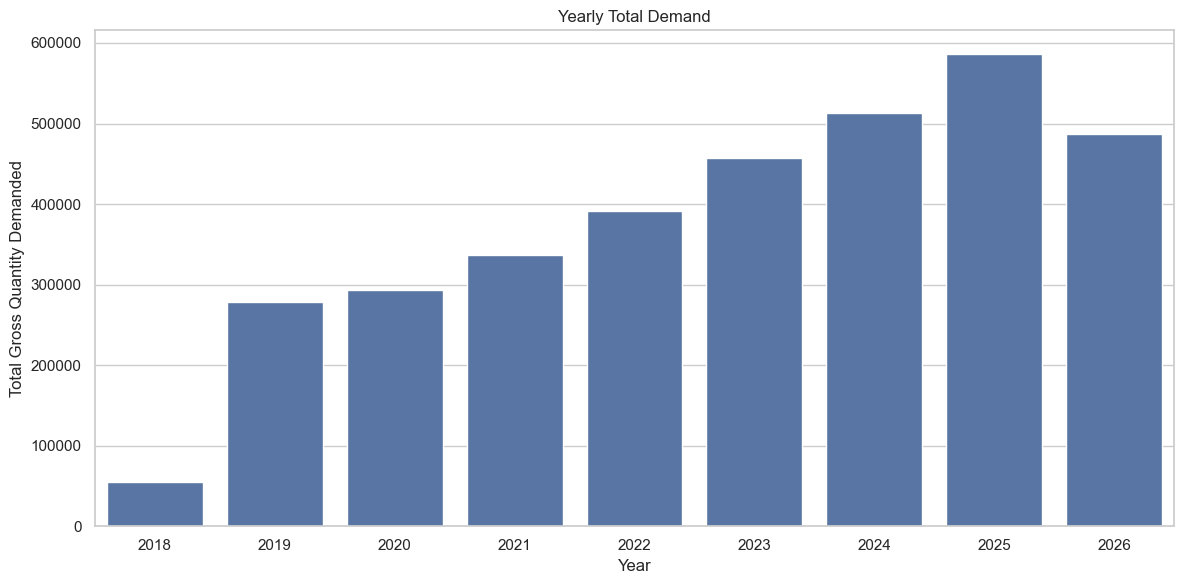

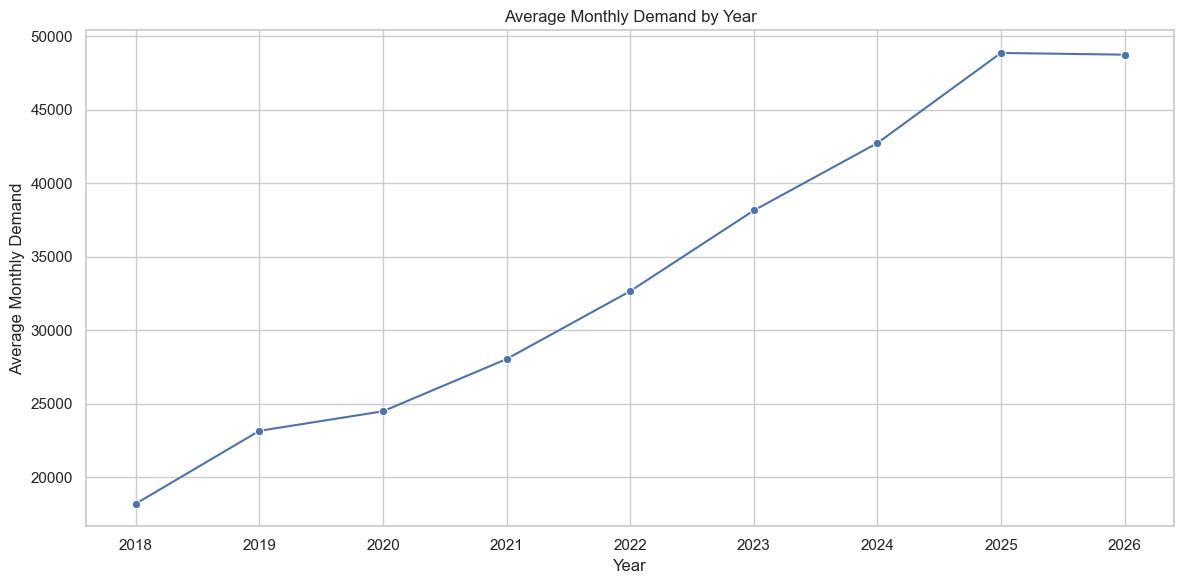

In [22]:
# Extract year
monthly_company_demand["year"] = (
    monthly_company_demand["month"].dt.year
)

# Aggregate demand by year
yearly_demand = (
    monthly_company_demand
    .groupby("year", as_index=False)
    .agg(
        total_demand=("total_demand", "sum"),
        average_monthly_demand=("total_demand", "mean"),
        observed_months=("month", "nunique"),
        average_active_branches=("active_branches", "mean")
    )
)

display(yearly_demand)

# Plot yearly total demand
plt.figure(figsize=(12, 6))

sns.barplot(
    data=yearly_demand,
    x="year",
    y="total_demand"
)

plt.title("Yearly Total Demand")
plt.xlabel("Year")
plt.ylabel("Total Gross Quantity Demanded")

plt.tight_layout()
plt.show()

# Plot average monthly demand
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=yearly_demand,
    x="year",
    y="average_monthly_demand",
    marker="o"
)

plt.title("Average Monthly Demand by Year")
plt.xlabel("Year")
plt.ylabel("Average Monthly Demand")

plt.tight_layout()
plt.show()

In [23]:
# Calculate correlation for each product
product_branch_correlation = (
    monthly_product_demand
    .groupby("product_id")
    .apply(
        lambda group: group["active_branches"].corr(
            group["gross_quantity_demanded"]
        ),
        include_groups=False
    )
    .rename("branch_demand_correlation")
    .reset_index()
)

# Count observations for each product
product_observations = (
    monthly_product_demand
    .groupby("product_id")
    .size()
    .rename("observations")
    .reset_index()
)

# Combine correlation and observation counts
product_branch_correlation = (
    product_branch_correlation
    .merge(product_observations, on="product_id")
)

# Keep products with sufficient historical observations
product_branch_correlation = (
    product_branch_correlation[
        product_branch_correlation["observations"] >= 6
    ]
    .sort_values("branch_demand_correlation", ascending=False)
    .reset_index(drop=True)
)

display(product_branch_correlation.head(20))

print(
    "Average product-level correlation:",
    round(
        product_branch_correlation[
            "branch_demand_correlation"
        ].mean(),
        3
    )
)

,product_id,branch_demand_correlation,observations
0,PR0066,0.57,97
1,PR0121,0.55,97
2,PR0094,0.55,97
3,PR0078,0.54,97
4,PR0131,0.54,97
5,PR0133,0.54,97
6,PR0134,0.54,97
7,PR0123,0.53,97
8,PR0119,0.53,97
9,PR0085,0.53,97


Average product-level correlation: 0.426


In [24]:
# Extract calendar components
monthly_product_demand["year"] = (
    monthly_product_demand["month"].dt.year
)

monthly_product_demand["month_number"] = (
    monthly_product_demand["month"].dt.month
)

monthly_product_demand["quarter"] = (
    monthly_product_demand["month"].dt.quarter
)

# Cyclical encoding for month seasonality
monthly_product_demand["month_sin"] = np.sin(
    2 * np.pi * monthly_product_demand["month_number"] / 12
)

monthly_product_demand["month_cos"] = np.cos(
    2 * np.pi * monthly_product_demand["month_number"] / 12
)

display(
    monthly_product_demand[
        [
            "month",
            "product_id",
            "year",
            "month_number",
            "quarter",
            "month_sin",
            "month_cos"
        ]
    ].head(12)
)

,month,product_id,year,month_number,quarter,month_sin,month_cos
0,2018-10-01,PR0001,2018,10,4,-0.87,0.50
1,2018-11-01,PR0001,2018,11,4,-0.50,0.87
2,2018-12-01,PR0001,2018,12,4,-0.00,1.00
3,2019-01-01,PR0001,2019,1,1,0.50,0.87
4,2019-02-01,PR0001,2019,2,1,0.87,0.50
5,2019-03-01,PR0001,2019,3,1,1.00,0.00
6,2019-04-01,PR0001,2019,4,2,0.87,-0.50
7,2019-05-01,PR0001,2019,5,2,0.50,-0.87
8,2019-06-01,PR0001,2019,6,2,0.00,-1.00
9,2019-07-01,PR0001,2019,7,3,-0.50,-0.87


In [25]:
product_features = products[
    [
        "product_id",
        "category_en",
        "audience",
        "listed_price_EGP"
    ]
].drop_duplicates(subset="product_id")

monthly_product_demand = monthly_product_demand.drop(
    columns=[
        "category_en",
        "audience",
        "listed_price_EGP"
    ],
    errors="ignore"
)

monthly_product_demand = monthly_product_demand.merge(
    product_features,
    on="product_id",
    how="left",
    validate="many_to_one"
)

display(
    monthly_product_demand[
        [
            "month",
            "product_id",
            "category_en",
            "audience",
            "listed_price_EGP"
        ]
    ].head(10)
)

,month,product_id,category_en,audience,listed_price_EGP
0,2018-10-01,PR0001,Socks,Men,290
1,2018-11-01,PR0001,Socks,Men,290
2,2018-12-01,PR0001,Socks,Men,290
3,2019-01-01,PR0001,Socks,Men,290
4,2019-02-01,PR0001,Socks,Men,290
5,2019-03-01,PR0001,Socks,Men,290
6,2019-04-01,PR0001,Socks,Men,290
7,2019-05-01,PR0001,Socks,Men,290
8,2019-06-01,PR0001,Socks,Men,290
9,2019-07-01,PR0001,Socks,Men,290


In [26]:
lag_periods = [1, 2, 3, 6, 12, 13]

monthly_product_demand = (
    monthly_product_demand
    .sort_values(["product_id", "month"])
    .reset_index(drop=True)
)

for lag in lag_periods:
    monthly_product_demand[f"lag_{lag}"] = (
        monthly_product_demand
        .groupby("product_id")["gross_quantity_demanded"]
        .shift(lag)
    )

display(
    monthly_product_demand[
        [
            "month",
            "product_id",
            "gross_quantity_demanded",
            "lag_1",
            "lag_2",
            "lag_3",
            "lag_6",
            "lag_12",
            "lag_13"
        ]
    ].head(20)
)

,month,product_id,gross_quantity_demanded,lag_1,lag_2,lag_3,lag_6,lag_12,lag_13
0,2018-10-01,PR0001,12,NaN,NaN,NaN,NaN,NaN,NaN
1,2018-11-01,PR0001,36,12.00,NaN,NaN,NaN,NaN,NaN
2,2018-12-01,PR0001,77,36.00,12.00,NaN,NaN,NaN,NaN
3,2019-01-01,PR0001,37,77.00,36.00,12.00,NaN,NaN,NaN
4,2019-02-01,PR0001,20,37.00,77.00,36.00,NaN,NaN,NaN
5,2019-03-01,PR0001,64,20.00,37.00,77.00,NaN,NaN,NaN
6,2019-04-01,PR0001,50,64.00,20.00,37.00,12.00,NaN,NaN
7,2019-05-01,PR0001,55,50.00,64.00,20.00,36.00,NaN,NaN
8,2019-06-01,PR0001,34,55.00,50.00,64.00,77.00,NaN,NaN
9,2019-07-01,PR0001,37,34.00,55.00,50.00,37.00,NaN,NaN


In [27]:
# Define rolling windows
rolling_windows = [3, 6, 12]

# Sort observations chronologically within each product
monthly_product_demand = (
    monthly_product_demand
    .sort_values(["product_id", "month"])
    .reset_index(drop=True)
)

# Create rolling features
for window in rolling_windows:

    monthly_product_demand[f"rolling_mean_{window}"] = (
        monthly_product_demand
        .groupby("product_id")["gross_quantity_demanded"]
        .transform(
            lambda x: x.shift(1).rolling(
                window=window,
                min_periods=1
            ).mean()
        )
    )

    monthly_product_demand[f"rolling_std_{window}"] = (
        monthly_product_demand
        .groupby("product_id")["gross_quantity_demanded"]
        .transform(
            lambda x: x.shift(1).rolling(
                window=window,
                min_periods=2
            ).std()
        )
    )

display(
    monthly_product_demand[
        [
            "month",
            "product_id",
            "gross_quantity_demanded",
            "rolling_mean_3",
            "rolling_std_3",
            "rolling_mean_6",
            "rolling_std_6",
            "rolling_mean_12",
            "rolling_std_12"
        ]
    ].head(20)
)

,month,product_id,gross_quantity_demanded,rolling_mean_3,rolling_std_3,rolling_mean_6,rolling_std_6,rolling_mean_12,rolling_std_12
0,2018-10-01,PR0001,12,NaN,NaN,NaN,NaN,NaN,NaN
1,2018-11-01,PR0001,36,12.00,NaN,12.00,NaN,12.00,NaN
2,2018-12-01,PR0001,77,24.00,16.97,24.00,16.97,24.00,16.97
3,2019-01-01,PR0001,37,41.67,32.87,41.67,32.87,41.67,32.87
4,2019-02-01,PR0001,20,50.00,23.39,40.50,26.94,40.50,26.94
5,2019-03-01,PR0001,64,44.67,29.26,36.40,25.07,36.40,25.07
6,2019-04-01,PR0001,50,40.33,22.19,41.00,25.09,41.00,25.09
7,2019-05-01,PR0001,55,44.67,22.48,47.33,20.72,42.29,23.16
8,2019-06-01,PR0001,34,56.33,7.09,50.50,20.09,43.88,21.91
9,2019-07-01,PR0001,37,46.33,10.97,43.33,16.00,42.78,20.75


In [28]:
# Demand change compared to previous month
monthly_product_demand["demand_change_1"] = (
    monthly_product_demand["gross_quantity_demanded"]
    - monthly_product_demand["lag_1"]
)

monthly_product_demand["demand_pct_change_1"] = (
    monthly_product_demand["gross_quantity_demanded"]
    .div(monthly_product_demand["lag_1"].replace(0, np.nan))
    .sub(1)
)

# Demand change compared to three months ago
monthly_product_demand["demand_change_3"] = (
    monthly_product_demand["gross_quantity_demanded"]
    - monthly_product_demand["lag_3"]
)

monthly_product_demand["demand_pct_change_3"] = (
    monthly_product_demand["gross_quantity_demanded"]
    .div(monthly_product_demand["lag_3"].replace(0, np.nan))
    .sub(1)
)

display(
    monthly_product_demand[
        [
            "month",
            "product_id",
            "gross_quantity_demanded",
            "lag_1",
            "lag_3",
            "demand_change_1",
            "demand_pct_change_1",
            "demand_change_3",
            "demand_pct_change_3"
        ]
    ].head(20)
)

,month,product_id,gross_quantity_demanded,lag_1,lag_3,demand_change_1,demand_pct_change_1,demand_change_3,demand_pct_change_3
0,2018-10-01,PR0001,12,NaN,NaN,NaN,NaN,NaN,NaN
1,2018-11-01,PR0001,36,12.00,NaN,24.00,2.00,NaN,NaN
2,2018-12-01,PR0001,77,36.00,NaN,41.00,1.14,NaN,NaN
3,2019-01-01,PR0001,37,77.00,12.00,-40.00,-0.52,25.00,2.08
4,2019-02-01,PR0001,20,37.00,36.00,-17.00,-0.46,-16.00,-0.44
5,2019-03-01,PR0001,64,20.00,77.00,44.00,2.20,-13.00,-0.17
6,2019-04-01,PR0001,50,64.00,37.00,-14.00,-0.22,13.00,0.35
7,2019-05-01,PR0001,55,50.00,20.00,5.00,0.10,35.00,1.75
8,2019-06-01,PR0001,34,55.00,64.00,-21.00,-0.38,-30.00,-0.47
9,2019-07-01,PR0001,37,34.00,50.00,3.00,0.09,-13.00,-0.26


In [29]:
print(f"Dataset shape: {monthly_product_demand.shape}")

print(
    f"Number of products: "
    f"{monthly_product_demand['product_id'].nunique():,}"
)

print(
    f"Date range: "
    f"{monthly_product_demand['month'].min().date()} "
    f"to "
    f"{monthly_product_demand['month'].max().date()}"
)

print("\nEngineered Features:")

display(
    pd.DataFrame({
        "column": monthly_product_demand.columns,
        "dtype": monthly_product_demand.dtypes.astype(str).values,
        "missing_values": monthly_product_demand.isna().sum().values
    })
)

Dataset shape: (13483, 28)
Number of products: 139
Date range: 2018-10-01 to 2026-10-01

Engineered Features:


,column,dtype,missing_values
0,product_id,object,0
1,month,datetime64[ns],0
2,gross_quantity_demanded,int64,0
3,active_branches,int64,0
4,month_number,int32,0
5,year,int32,0
6,quarter,int32,0
7,month_sin,float64,0
8,month_cos,float64,0
9,category_en,object,0


In [30]:
# Define target variable
target = "gross_quantity_demanded"

# Define categorical features
categorical_features = [
    "product_id",
    "category_en",
    "audience"
]

# Define numerical features
numerical_features = [
    "listed_price_EGP",
    "active_branches",
    "year",
    "month_number",
    "quarter",
    "month_sin",
    "month_cos",

    "lag_1",
    "lag_2",
    "lag_3",
    "lag_6",
    "lag_12",
    "lag_13",

    "rolling_mean_3",
    "rolling_std_3",
    "rolling_mean_6",
    "rolling_std_6",
    "rolling_mean_12",
    "rolling_std_12"
]

# Combine all model features
feature_columns = (
    categorical_features + numerical_features
)

# Prepare X and y
X = monthly_product_demand[feature_columns].copy()
y = monthly_product_demand[target].copy()

# Convert categorical features to strings
for col in categorical_features:
    X[col] = X[col].astype(str)

print(f"Number of features: {len(feature_columns)}")
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

display(X.head())

Number of features: 22
X shape: (13483, 22)
y shape: (13483,)


,product_id,category_en,audience,listed_price_EGP,active_branches,year,month_number,quarter,month_sin,month_cos,lag_1,lag_2,lag_3,lag_6,lag_12,lag_13,rolling_mean_3,rolling_std_3,rolling_mean_6,rolling_std_6,rolling_mean_12,rolling_std_12
0,PR0001,Socks,Men,290,0,2018,10,4,-0.87,0.50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,PR0001,Socks,Men,290,0,2018,11,4,-0.50,0.87,12.00,NaN,NaN,NaN,NaN,NaN,12.00,NaN,12.00,NaN,12.00,NaN
2,PR0001,Socks,Men,290,6,2018,12,4,-0.00,1.00,36.00,12.00,NaN,NaN,NaN,NaN,24.00,16.97,24.00,16.97,24.00,16.97
3,PR0001,Socks,Men,290,10,2019,1,1,0.50,0.87,77.00,36.00,12.00,NaN,NaN,NaN,41.67,32.87,41.67,32.87,41.67,32.87
4,PR0001,Socks,Men,290,14,2019,2,1,0.87,0.50,37.00,77.00,36.00,NaN,NaN,NaN,50.00,23.39,40.50,26.94,40.50,26.94


In [31]:
# Monthly date range
date_summary = (
    monthly_product_demand
    .groupby("month")
    .agg(
        observations=("product_id", "count"),
        products=("product_id", "nunique"),
        total_demand=(target, "sum")
    )
    .reset_index()
)

display(date_summary)

print("First month:", date_summary["month"].min())
print("Last month:", date_summary["month"].max())
print("Number of months:", len(date_summary))

,month,observations,products,total_demand
0,2018-10-01,139,139,7611
1,2018-11-01,139,139,22492
2,2018-12-01,139,139,24490
3,2019-01-01,139,139,21133
4,2019-02-01,139,139,19254
5,2019-03-01,139,139,24735
6,2019-04-01,139,139,23895
7,2019-05-01,139,139,25360
8,2019-06-01,139,139,20847
9,2019-07-01,139,139,20459


First month: 2018-10-01 00:00:00
Last month: 2026-10-01 00:00:00
Number of months: 97


In [32]:
# Define split boundaries
train_end = pd.Timestamp("2024-12-01")
validation_start = pd.Timestamp("2025-01-01")
validation_end = pd.Timestamp("2025-12-01")
test_start = pd.Timestamp("2026-01-01")

# Identify the latest fully completed month
latest_data_date = sales_items["order_date"].max()

latest_completed_month = (
    latest_data_date.to_period("M") - 1
).to_timestamp()

test_end = min(
    latest_completed_month,
    monthly_product_demand["month"].max()
)

# Create chronological masks
train_mask = monthly_product_demand["month"] <= train_end

validation_mask = (
    (monthly_product_demand["month"] >= validation_start) &
    (monthly_product_demand["month"] <= validation_end)
)

test_mask = (
    (monthly_product_demand["month"] >= test_start) &
    (monthly_product_demand["month"] <= test_end)
)

# Split datasets
X_train = X.loc[train_mask].copy()
y_train = y.loc[train_mask].copy()

X_val = X.loc[validation_mask].copy()
y_val = y.loc[validation_mask].copy()

X_test = X.loc[test_mask].copy()
y_test = y.loc[test_mask].copy()

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

print("\nTest period:", test_start.date(), "to", test_end.date())

Training: (10425, 22) (10425,)
Validation: (1668, 22) (1668,)
Testing: (1251, 22) (1251,)

Test period: 2026-01-01 to 2026-09-01


In [33]:
# Create baseline predictions
baseline_predictions = pd.DataFrame(index=X_val.index)

baseline_predictions["Naive_Lag_1"] = X_val["lag_1"]

baseline_predictions["Seasonal_Naive_Lag_12"] = (
    X_val["lag_12"]
)

baseline_predictions["Moving_Average_3"] = (
    X_val["rolling_mean_3"]
)

# Evaluation function
def evaluate_forecast(y_true, y_pred):

    results = pd.DataFrame({
        "actual": y_true,
        "predicted": y_pred
    }).dropna()

    mae = mean_absolute_error(
        results["actual"],
        results["predicted"]
    )

    rmse = np.sqrt(
        mean_squared_error(
            results["actual"],
            results["predicted"]
        )
    )

    wape = (
        np.abs(
            results["actual"] - results["predicted"]
        ).sum()
        / results["actual"].sum()
    ) * 100

    bias = (
        results["predicted"] - results["actual"]
    ).sum() / results["actual"].sum() * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE (%)": wape,
        "Bias (%)": bias,
        "Observations": len(results)
    }


# Evaluate baseline models
baseline_results = {}

for model_name in baseline_predictions.columns:

    baseline_results[model_name] = evaluate_forecast(
        y_val,
        baseline_predictions[model_name]
    )

baseline_results = (
    pd.DataFrame(baseline_results)
    .T
    .sort_values("WAPE (%)")
)

display(baseline_results)

,MAE,RMSE,WAPE (%),Bias (%),Observations
Moving_Average_3,66.12,93.55,18.81,-2.08,"1,668.00"
Seasonal_Naive_Lag_12,73.15,101.93,20.81,-12.55,"1,668.00"
Naive_Lag_1,75.53,106.87,21.49,-1.02,"1,668.00"


In [34]:
# Categorical feature indices
cat_feature_indices = [
    X_train.columns.get_loc(col)
    for col in categorical_features
]

# Verify training and validation periods
print("Training period:")
print(
    monthly_product_demand.loc[train_mask, "month"].min(),
    "to",
    monthly_product_demand.loc[train_mask, "month"].max()
)

print("\nValidation period:")
print(
    monthly_product_demand.loc[validation_mask, "month"].min(),
    "to",
    monthly_product_demand.loc[validation_mask, "month"].max()
)

print("\nCategorical features:")
print(categorical_features)

print("\nCategorical feature indices:")
print(cat_feature_indices)

Training period:
2018-10-01 00:00:00 to 2024-12-01 00:00:00

Validation period:
2025-01-01 00:00:00 to 2025-12-01 00:00:00

Categorical features:
['product_id', 'category_en', 'audience']

Categorical feature indices:
[0, 1, 2]


In [35]:
param_grid = {
    "iterations": [500, 700, 1000],
    "depth": [4, 6, 8],
    "learning_rate": [0.03, 0.05, 0.1],
    "l2_leaf_reg": [3, 5, 7, 9],
    "random_strength": [0.5, 1, 2],
    "bagging_temperature": [0, 0.5, 1]
}

In [36]:
# Generate reproducible random combinations
rng = np.random.default_rng(42)

param_names = list(param_grid.keys())

all_combinations = [
    dict(zip(param_names, values))
    for values in __import__("itertools").product(
        *param_grid.values()
    )
]

selected_indices = rng.choice(
    len(all_combinations),
    size=min(20, len(all_combinations)),
    replace=False
)

selected_params = [
    all_combinations[i]
    for i in selected_indices
]

# Store tuning results
tuning_results = []

best_wape = float("inf")
best_params = None
best_model = None

# Run randomized search
for trial, params in enumerate(selected_params, start=1):

    model = CatBoostRegressor(
        **params,
        loss_function="RMSE",
        random_seed=42,
        verbose=False,
        allow_writing_files=False,
        thread_count=-1
    )

    model.fit(
        X_train,
        y_train,
        cat_features=cat_feature_indices
    )

    val_predictions = model.predict(X_val)

    # Demand cannot be negative
    val_predictions = np.maximum(val_predictions, 0)

    metrics = evaluate_forecast(
        y_val,
        val_predictions
    )

    trial_result = {
        "trial": trial,
        **params,
        **metrics
    }

    tuning_results.append(trial_result)

    if metrics["WAPE (%)"] < best_wape:
        best_wape = metrics["WAPE (%)"]
        best_params = params.copy()
        best_model = model

    print(
        f"Trial {trial:02d}/20 | "
        f"Validation WAPE: {metrics['WAPE (%)']:.2f}%"
    )

# Display all tuning results
tuning_results = (
    pd.DataFrame(tuning_results)
    .sort_values("WAPE (%)")
    .reset_index(drop=True)
)

print("\nBest Hyperparameters:")
print(best_params)

print(f"\nBest Validation WAPE: {best_wape:.2f}%")

display(tuning_results)

Trial 01/20 | Validation WAPE: 14.96%
Trial 02/20 | Validation WAPE: 14.68%
Trial 03/20 | Validation WAPE: 14.90%
Trial 04/20 | Validation WAPE: 15.26%
Trial 05/20 | Validation WAPE: 14.79%
Trial 06/20 | Validation WAPE: 14.97%
Trial 07/20 | Validation WAPE: 14.45%
Trial 08/20 | Validation WAPE: 14.76%
Trial 09/20 | Validation WAPE: 15.21%
Trial 10/20 | Validation WAPE: 14.80%
Trial 11/20 | Validation WAPE: 14.79%
Trial 12/20 | Validation WAPE: 14.78%
Trial 13/20 | Validation WAPE: 14.66%
Trial 14/20 | Validation WAPE: 14.77%
Trial 15/20 | Validation WAPE: 14.73%
Trial 16/20 | Validation WAPE: 14.63%
Trial 17/20 | Validation WAPE: 14.68%
Trial 18/20 | Validation WAPE: 14.81%
Trial 19/20 | Validation WAPE: 14.43%
Trial 20/20 | Validation WAPE: 14.95%

Best Hyperparameters:
{'iterations': 1000, 'depth': 4, 'learning_rate': 0.03, 'l2_leaf_reg': 7, 'random_strength': 1, 'bagging_temperature': 0}

Best Validation WAPE: 14.43%


,trial,iterations,depth,learning_rate,l2_leaf_reg,random_strength,bagging_temperature,MAE,RMSE,WAPE (%),Bias (%),Observations
0,19,1000,4,0.03,7,1.00,0.00,50.71,72.47,14.43,-5.06,1668
1,7,500,6,0.03,5,2.00,0.50,50.80,72.98,14.45,-6.01,1668
2,16,1000,4,0.05,7,2.00,1.00,51.42,74.37,14.63,-6.24,1668
3,13,700,6,0.03,3,1.00,1.00,51.52,73.34,14.66,-5.36,1668
4,2,1000,4,0.05,5,0.50,0.00,51.60,74.23,14.68,-5.52,1668
5,17,1000,6,0.03,3,1.00,0.50,51.61,73.96,14.68,-5.86,1668
6,15,500,4,0.10,7,0.50,0.00,51.78,73.87,14.73,-5.18,1668
7,8,500,4,0.10,5,1.00,0.50,51.88,74.60,14.76,-5.98,1668
8,14,1000,6,0.05,9,1.00,0.00,51.91,74.69,14.77,-6.57,1668
9,12,500,4,0.10,5,0.50,0.50,51.94,74.26,14.78,-5.35,1668


In [37]:
# Get the top 6 tuning trials
top_6_trials = tuning_results.head(6).copy()

# Exclude the best trial and calculate average bias
average_bias = top_6_trials.iloc[1:]["Bias (%)"].max()

# Calculate correction factor
correction_factor = 1 - (average_bias / 100)

print(f"Average Bias of Trials 2-6: {average_bias:.2f}%")
print(f"Correction Factor: {correction_factor:.4f}")

# Generate best CatBoost predictions
best_predictions = np.maximum(
    best_model.predict(X_val),
    0
)

# Apply bias correction
corrected_predictions = np.maximum(
    best_predictions * correction_factor,
    0
)

# Collect all predictions
all_predictions = {
    "Naive Lag 1": X_val["lag_1"],
    "Seasonal Naive Lag 12": X_val["lag_12"],
    "Moving Average 3": X_val["rolling_mean_3"],
    "Best CatBoost": best_predictions,
    "Corrected CatBoost": corrected_predictions
}

# Evaluate all models
comparison_results = {}

for model_name, predictions in all_predictions.items():
    comparison_results[model_name] = evaluate_forecast(
        y_val,
        predictions
    )

comparison_results = (
    pd.DataFrame(comparison_results)
    .T
    .sort_values("WAPE (%)")
)

display(comparison_results)

Average Bias of Trials 2-6: -5.36%
Correction Factor: 1.0536


,MAE,RMSE,WAPE (%),Bias (%),Observations
Corrected CatBoost,49.87,69.36,14.19,0.03,"1,668.00"
Best CatBoost,50.71,72.47,14.43,-5.06,"1,668.00"
Moving Average 3,66.12,93.55,18.81,-2.08,"1,668.00"
Seasonal Naive Lag 12,73.15,101.93,20.81,-12.55,"1,668.00"
Naive Lag 1,75.53,106.87,21.49,-1.02,"1,668.00"


In [78]:
# Calculate total profit per product
product_profit = (
    sales_items
    .groupby("product_id", as_index=False)
    .agg(total_profit=("margin_EGP", "sum"))
    .sort_values("total_profit", ascending=False)
    .reset_index(drop=True)
)

# Calculate total company profit
total_company_profit = product_profit["total_profit"].sum()

# Select top 10 products
top_10_products = product_profit.head(20).copy()

# Calculate profit share
top_10_products["profit_share"] = (
    top_10_products["total_profit"] / total_company_profit
) * 100

# Aggregate remaining products as Other
other_profit = product_profit.iloc[20:]["total_profit"].sum()

other_row = pd.DataFrame({
    "product_id": ["Other"],
    "total_profit": [other_profit],
    "profit_share": [(other_profit / total_company_profit) * 100]
})

# Prepare chart data
profit_share_chart = pd.concat(
    [
        top_10_products[["product_id", "total_profit", "profit_share"]],
        other_row
    ],
    ignore_index=True
)

# Create column chart
fig = px.bar(
    profit_share_chart,
    x="product_id",
    y="profit_share",
    text=profit_share_chart["profit_share"].map(lambda x: f"{x:.2f}%"),
    hover_data={
        "total_profit": ":,.2f",
        "profit_share": ":.2f"
    },
    title="Top 10 Products by Share in Total Profit",
    labels={
        "product_id": "Product ID",
        "profit_share": "Share in Total Profit (%)",
        "total_profit": "Total Profit (EGP)"
    }
)

fig.update_traces(
    textposition="outside",
    cliponaxis=False
)

fig.update_layout(
    xaxis_title="Product ID",
    yaxis_title="Profit Share (%)",
    showlegend=False
)

fig.show()

display(profit_share_chart)

,product_id,total_profit,profit_share
0,PR0060,"24,029,662.06",7.45
1,PR0090,"14,662,698.68",4.55
2,PR0121,"11,752,566.67",3.64
3,PR0081,"10,791,195.16",3.35
4,PR0085,"10,350,852.39",3.21
5,PR0122,"9,674,418.33",3.00
6,PR0123,"9,569,254.22",2.97
7,PR0137,"8,963,952.17",2.78
8,PR0086,"8,615,756.71",2.67
9,PR0120,"7,935,567.78",2.46


In [79]:

# ============================================================
# TOP 20 PRODUCTS - SKU LEVEL DEMAND FORECASTING
# GLOBAL CATBOOST + HYPERPARAMETER TUNING + BIAS CORRECTION
# ============================================================

from itertools import product as cartesian_product

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

RANDOM_SEED = 42
N_TRIALS = 20

TRAIN_END = pd.Timestamp("2024-12-01")
VALIDATION_START = pd.Timestamp("2025-01-01")
VALIDATION_END = pd.Timestamp("2025-12-01")
TEST_START = pd.Timestamp("2026-01-01")

TARGET = "gross_quantity_demanded"

CATEGORICAL_FEATURES = [
    "product_id",
    "sku_id",
    "category_en",
    "audience"
]

LAG_PERIODS = [1, 2, 3, 6, 12, 13]
ROLLING_WINDOWS = [3, 6, 12]

# ------------------------------------------------------------
# 2. IDENTIFY TOP 20 PRODUCTS BY PROFIT
# ------------------------------------------------------------

product_profit = (
    sales_items
    .groupby("product_id", as_index=False)
    .agg(total_profit=("margin_EGP", "sum"))
    .sort_values("total_profit", ascending=False)
    .reset_index(drop=True)
)

top_20_products = product_profit.head(20).copy()

selected_product_ids = top_20_products["product_id"].tolist()

print(f"Selected products: {len(selected_product_ids)}")

# ------------------------------------------------------------
# 3. EXTRACT ALL ASSOCIATED SKUs
# ------------------------------------------------------------

sku_product_map = (
    sales_items[
        sales_items["product_id"].isin(selected_product_ids)
    ][["product_id", "sku_id"]]
    .dropna(subset=["sku_id"])
    .drop_duplicates()
)

if sku_product_map["sku_id"].duplicated().any():
    raise ValueError(
        "A SKU is associated with multiple Product IDs. "
        "Please investigate the SKU mapping before forecasting."
    )

selected_skus = sku_product_map["sku_id"].tolist()

print(f"Selected SKUs: {len(selected_skus)}")

# ------------------------------------------------------------
# 4. DETERMINE LAST COMPLETED MONTH
# ------------------------------------------------------------

latest_data_date = sales_items["order_date"].max()

if latest_data_date.normalize() == latest_data_date.to_period("M").end_time.normalize():
    last_completed_month = latest_data_date.to_period("M").to_timestamp()
else:
    last_completed_month = (
        latest_data_date.to_period("M") - 1
    ).to_timestamp()

print(f"Last completed month: {last_completed_month:%Y-%m}")

# ------------------------------------------------------------
# 5. AGGREGATE MONTHLY DEMAND PER SKU
# ------------------------------------------------------------

sku_monthly_demand = (
    sales_items[
        sales_items["sku_id"].isin(selected_skus)
    ]
    .assign(
        month=lambda df: df["order_date"].dt.to_period("M").dt.to_timestamp()
    )
    .groupby(
        ["product_id", "sku_id", "month"],
        as_index=False
    )
    .agg(
        gross_quantity_demanded=("quantity", "sum")
    )
)

# Exclude incomplete months from historical training data
sku_monthly_demand = sku_monthly_demand[
    sku_monthly_demand["month"] <= last_completed_month
].copy()

# ------------------------------------------------------------
# 6. BUILD COMPLETE SKU-MONTH GRID
# ------------------------------------------------------------

sku_monthly_data = []

for row in sku_product_map.itertuples(index=False):

    product_id = row.product_id
    sku_id = row.sku_id

    sku_history = sku_monthly_demand[
        sku_monthly_demand["sku_id"] == sku_id
    ].copy()

    if sku_history.empty:
        continue

    first_demand_month = sku_history.loc[
        sku_history[TARGET] > 0,
        "month"
    ].min()

    if pd.isna(first_demand_month):
        continue

    months = pd.date_range(
        start=first_demand_month,
        end=last_completed_month,
        freq="MS"
    )

    sku_grid = pd.DataFrame({
        "product_id": product_id,
        "sku_id": sku_id,
        "month": months
    })

    sku_grid = sku_grid.merge(
        sku_history[["sku_id", "month", TARGET]],
        on=["sku_id", "month"],
        how="left"
    )

    sku_grid[TARGET] = sku_grid[TARGET].fillna(0)

    sku_monthly_data.append(sku_grid)

if not sku_monthly_data:
    raise ValueError("No historical SKU demand data is available.")

sku_monthly_demand = pd.concat(
    sku_monthly_data,
    ignore_index=True
)

sku_monthly_demand = (
    sku_monthly_demand
    .sort_values(["sku_id", "month"])
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 7. MERGE PRODUCT INFORMATION
# ------------------------------------------------------------

product_features = (
    products[
        ["product_id", "category_en", "audience"]
    ]
    .drop_duplicates(subset="product_id")
)

sku_monthly_demand = sku_monthly_demand.merge(
    product_features,
    on="product_id",
    how="left",
    validate="many_to_one"
)

sku_monthly_demand[["category_en", "audience"]] = (
    sku_monthly_demand[["category_en", "audience"]]
    .fillna("Unknown")
)

# ------------------------------------------------------------
# 8. CALCULATE MONTHLY ACTIVE BRANCHES
# ------------------------------------------------------------

monthly_branch_count = pd.DataFrame({
    "month": pd.date_range(
        sku_monthly_demand["month"].min(),
        sku_monthly_demand["month"].max(),
        freq="MS"
    )
})

monthly_branch_count["active_branches"] = (
    monthly_branch_count["month"]
    .apply(
        lambda month: (
            branches["opening_date"] <= month
        ).sum()
    )
)

sku_monthly_demand = sku_monthly_demand.merge(
    monthly_branch_count,
    on="month",
    how="left",
    validate="many_to_one"
)

# ------------------------------------------------------------
# 9. CALENDAR FEATURES
# ------------------------------------------------------------

sku_monthly_demand["year"] = sku_monthly_demand["month"].dt.year
sku_monthly_demand["month_number"] = sku_monthly_demand["month"].dt.month
sku_monthly_demand["quarter"] = sku_monthly_demand["month"].dt.quarter

sku_monthly_demand["month_sin"] = np.sin(
    2 * np.pi * sku_monthly_demand["month_number"] / 12
)

sku_monthly_demand["month_cos"] = np.cos(
    2 * np.pi * sku_monthly_demand["month_number"] / 12
)

# ------------------------------------------------------------
# 10. LAG FEATURES
# ------------------------------------------------------------

sku_monthly_demand = (
    sku_monthly_demand
    .sort_values(["sku_id", "month"])
    .reset_index(drop=True)
)

for lag in LAG_PERIODS:

    sku_monthly_demand[f"lag_{lag}"] = (
        sku_monthly_demand
        .groupby("sku_id")[TARGET]
        .shift(lag)
    )

# ------------------------------------------------------------
# 11. ROLLING FEATURES
# ------------------------------------------------------------

for window in ROLLING_WINDOWS:

    sku_monthly_demand[f"rolling_mean_{window}"] = (
        sku_monthly_demand
        .groupby("sku_id")[TARGET]
        .transform(
            lambda x: (
                x.shift(1)
                .rolling(window=window, min_periods=1)
                .mean()
            )
        )
    )

    sku_monthly_demand[f"rolling_std_{window}"] = (
        sku_monthly_demand
        .groupby("sku_id")[TARGET]
        .transform(
            lambda x: (
                x.shift(1)
                .rolling(window=window, min_periods=2)
                .std()
            )
        )
    )

# ------------------------------------------------------------
# 12. DEFINE MODEL FEATURES
# ------------------------------------------------------------

NUMERICAL_FEATURES = [
    "active_branches",
    "year",
    "month_number",
    "quarter",
    "month_sin",
    "month_cos"
]

for lag in LAG_PERIODS:
    NUMERICAL_FEATURES.append(f"lag_{lag}")

for window in ROLLING_WINDOWS:
    NUMERICAL_FEATURES.extend([
        f"rolling_mean_{window}",
        f"rolling_std_{window}"
    ])

FEATURE_COLUMNS = CATEGORICAL_FEATURES + NUMERICAL_FEATURES

for column in CATEGORICAL_FEATURES:
    sku_monthly_demand[column] = (
        sku_monthly_demand[column].astype(str)
    )

X = sku_monthly_demand[FEATURE_COLUMNS].copy()
y = sku_monthly_demand[TARGET].copy()

# ------------------------------------------------------------
# 13. CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT
# ------------------------------------------------------------

train_mask = sku_monthly_demand["month"] <= TRAIN_END

validation_mask = (
    (sku_monthly_demand["month"] >= VALIDATION_START) &
    (sku_monthly_demand["month"] <= VALIDATION_END)
)

test_mask = (
    (sku_monthly_demand["month"] >= TEST_START) &
    (sku_monthly_demand["month"] <= last_completed_month)
)

X_train = X.loc[train_mask].copy()
y_train = y.loc[train_mask].copy()

X_val = X.loc[validation_mask].copy()
y_val = y.loc[validation_mask].copy()

X_test = X.loc[test_mask].copy()
y_test = y.loc[test_mask].copy()

if X_train.empty or X_val.empty or X_test.empty:
    raise ValueError(
        "One of the chronological splits is empty. "
        "Check the available historical date range."
    )

print("\nSplit Summary")
print(f"Training observations: {len(X_train):,}")
print(f"Validation observations: {len(X_val):,}")
print(f"Testing observations: {len(X_test):,}")

# ------------------------------------------------------------
# 14. EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate_forecast(y_true, y_pred):

    results = pd.DataFrame({
        "actual": np.asarray(y_true),
        "predicted": np.asarray(y_pred)
    }).replace([np.inf, -np.inf], np.nan).dropna()

    actual = results["actual"]
    predicted = results["predicted"]

    total_actual = actual.sum()

    wape = (
        np.abs(actual - predicted).sum() / total_actual * 100
        if total_actual != 0 else np.nan
    )

    bias = (
        (predicted - actual).sum() / total_actual * 100
        if total_actual != 0 else np.nan
    )

    return {
        "WAPE (%)": wape,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "Bias (%)": bias,
        "Observations": len(results)
    }

# ------------------------------------------------------------
# 15. BASELINE MODELS
# ------------------------------------------------------------

baseline_predictions = {
    "Naive Lag 1": X_val["lag_1"],
    "Seasonal Naive Lag 12": X_val["lag_12"],
    "Moving Average 3": X_val["rolling_mean_3"]
}

# ------------------------------------------------------------
# 16. CATBOOST HYPERPARAMETER SEARCH SPACE
# ------------------------------------------------------------

param_grid = {
    "iterations": [500, 700, 1000],
    "depth": [4, 6, 8],
    "learning_rate": [0.03, 0.05, 0.1],
    "l2_leaf_reg": [3, 5, 7, 9],
    "random_strength": [0.5, 1, 2],
    "bagging_temperature": [0, 0.5, 1]
}

all_combinations = [
    dict(zip(param_grid.keys(), values))
    for values in cartesian_product(*param_grid.values())
]

rng = np.random.default_rng(RANDOM_SEED)

selected_indices = rng.choice(
    len(all_combinations),
    size=min(N_TRIALS, len(all_combinations)),
    replace=False
)

selected_params = [
    all_combinations[i] for i in selected_indices
]

cat_feature_indices = [
    X_train.columns.get_loc(column)
    for column in CATEGORICAL_FEATURES
]

# ------------------------------------------------------------
# 17. RANDOMIZED TUNING
# ------------------------------------------------------------

tuning_results = []

best_model = None
best_params = None
best_wape = float("inf")

for trial, params in enumerate(selected_params, start=1):

    model = CatBoostRegressor(
        **params,
        loss_function="RMSE",
        random_seed=RANDOM_SEED,
        verbose=False,
        allow_writing_files=False,
        thread_count=-1
    )

    model.fit(
        X_train,
        y_train,
        cat_features=cat_feature_indices
    )

    predictions = np.maximum(
        model.predict(X_val),
        0
    )

    metrics = evaluate_forecast(y_val, predictions)

    tuning_results.append({
        "trial": trial,
        **params,
        **metrics
    })

    if metrics["WAPE (%)"] < best_wape:

        best_wape = metrics["WAPE (%)"]
        best_params = params.copy()
        best_model = model

    print(
        f"Trial {trial:02d}/{len(selected_params)} | "
        f"Validation WAPE: {metrics['WAPE (%)']:.2f}%"
    )

tuning_results = (
    pd.DataFrame(tuning_results)
    .sort_values("WAPE (%)")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 18. CALCULATE BIAS CORRECTION
# ------------------------------------------------------------

top_6_trials = tuning_results.head(6).copy()

average_bias = top_6_trials.iloc[1:6]["Bias (%)"].mean()

correction_factor = 1 - (average_bias / 100)

print("\nBest Parameters:")
print(best_params)

print(f"Average Bias of Trials 2-6: {average_bias:.2f}%")
print(f"Correction Factor: {correction_factor:.4f}")

# ------------------------------------------------------------
# 19. REFIT FINAL MODEL ON TRAIN + VALIDATION
# ------------------------------------------------------------

X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

final_model = CatBoostRegressor(
    **best_params,
    loss_function="RMSE",
    random_seed=RANDOM_SEED,
    verbose=False,
    allow_writing_files=False,
    thread_count=-1
)

final_model.fit(
    X_train_val,
    y_train_val,
    cat_features=cat_feature_indices
)

# ------------------------------------------------------------
# 20. TEST SET PREDICTIONS
# ------------------------------------------------------------

best_test_predictions = np.maximum(
    final_model.predict(X_test),
    0
)

corrected_test_predictions = np.maximum(
    best_test_predictions * correction_factor,
    0
)

test_predictions = {
    "Naive Lag 1": X_test["lag_1"],
    "Seasonal Naive Lag 12": X_test["lag_12"],
    "Moving Average 3": X_test["rolling_mean_3"],
    "Best CatBoost": best_test_predictions,
    "Corrected CatBoost": corrected_test_predictions
}

# ------------------------------------------------------------
# 21. OVERALL TEST COMPARISON
# ------------------------------------------------------------

overall_model_comparison = pd.DataFrame({
    model_name: evaluate_forecast(y_test, predictions)
    for model_name, predictions in test_predictions.items()
}).T.sort_values("WAPE (%)")

print("\nOVERALL TEST MODEL COMPARISON")
display(overall_model_comparison)

# ------------------------------------------------------------
# 22. SKU-LEVEL TEST COMPARISON
# ------------------------------------------------------------

test_results = sku_monthly_demand.loc[
    test_mask,
    ["product_id", "sku_id", "month", TARGET]
].copy()

for model_name, predictions in test_predictions.items():
    test_results[model_name] = np.asarray(predictions)

sku_comparison_rows = []

for (product_id, sku_id), group in test_results.groupby(
    ["product_id", "sku_id"]
):

    for model_name in test_predictions:

        metrics = evaluate_forecast(
            group[TARGET],
            group[model_name]
        )

        sku_comparison_rows.append({
            "product_id": product_id,
            "sku_id": sku_id,
            "model": model_name,
            **metrics
        })

sku_forecast_comparison = pd.DataFrame(
    sku_comparison_rows
).sort_values(
    ["product_id", "sku_id", "WAPE (%)"]
).reset_index(drop=True)

print("\nSKU-LEVEL TEST COMPARISON")
display(sku_forecast_comparison)

# ------------------------------------------------------------
# 23. DETERMINE NEXT CALENDAR QUARTER
# ------------------------------------------------------------

today = pd.Timestamp.today().normalize()

next_quarter_start = (
    today.to_period("Q").end_time.normalize()
    + pd.Timedelta(days=1)
)

next_quarter_end = (
    next_quarter_start + pd.offsets.MonthEnd(2)
)

forecast_start = (
    last_completed_month + pd.offsets.MonthBegin(1)
)

forecast_months = pd.date_range(
    start=forecast_start,
    end=next_quarter_end,
    freq="MS"
)

print("\nForecast bridge:")
print(f"{forecast_start:%Y-%m} to {next_quarter_end:%Y-%m}")

print("\nTarget quarter:")
print(f"{next_quarter_start:%Y-%m} to {next_quarter_end:%Y-%m}")

# ------------------------------------------------------------
# 24. RECURSIVE SKU-LEVEL FORECASTING
# ------------------------------------------------------------

future_forecasts = []

# Historical demand for each SKU
sku_histories = {
    sku_id: group.sort_values("month")[TARGET].tolist()
    for sku_id, group in sku_monthly_demand.groupby("sku_id")
}

sku_metadata = (
    sku_monthly_demand[
        ["product_id", "sku_id", "category_en", "audience"]
    ]
    .drop_duplicates(subset="sku_id")
    .set_index("sku_id")
)

for sku_id, history in sku_histories.items():

    metadata = sku_metadata.loc[sku_id]
    product_id = metadata["product_id"]

    for forecast_month in forecast_months:

        # Calendar features
        month_number = forecast_month.month

        features = {
            "product_id": str(product_id),
            "sku_id": str(sku_id),
            "category_en": str(metadata["category_en"]),
            "audience": str(metadata["audience"]),
            "year": forecast_month.year,
            "month_number": month_number,
            "quarter": forecast_month.quarter,
            "month_sin": np.sin(2 * np.pi * month_number / 12),
            "month_cos": np.cos(2 * np.pi * month_number / 12),
            "active_branches": int(
                (branches["opening_date"] <= forecast_month).sum()
            )
        }

        # Lag features
        for lag in LAG_PERIODS:

            features[f"lag_{lag}"] = (
                history[-lag]
                if len(history) >= lag
                else np.nan
            )

        # Rolling features
        for window in ROLLING_WINDOWS:

            recent_values = history[-window:]

            features[f"rolling_mean_{window}"] = (
                np.mean(recent_values)
                if len(recent_values) >= 1
                else np.nan
            )

            features[f"rolling_std_{window}"] = (
                np.std(recent_values, ddof=1)
                if len(recent_values) >= 2
                else np.nan
            )

        future_X = pd.DataFrame(
            [features],
            columns=FEATURE_COLUMNS
        )

        raw_prediction = max(
            float(final_model.predict(future_X)[0]),
            0
        )

        corrected_prediction = max(
            raw_prediction * correction_factor,
            0
        )

        future_forecasts.append({
            "product_id": product_id,
            "sku_id": sku_id,
            "month": forecast_month,
            "best_catboost_forecast": raw_prediction,
            "corrected_forecast": corrected_prediction,
            "active_branches": features["active_branches"]
        })

        # Recursive update uses corrected forecast
        history.append(corrected_prediction)

# ------------------------------------------------------------
# 25. FINAL QUARTER FORECAST
# ------------------------------------------------------------

sku_forecasts = pd.DataFrame(future_forecasts)

# Keep only the target quarter in the final output
sku_forecasts = sku_forecasts[
    (sku_forecasts["month"] >= next_quarter_start) &
    (sku_forecasts["month"] <= next_quarter_end)
].copy()

sku_forecasts["quarter"] = (
    sku_forecasts["month"].dt.to_period("Q").astype(str)
)

sku_forecasts["forecast_quantity_rounded"] = np.ceil(
    sku_forecasts["corrected_forecast"]
).astype(int)

# ------------------------------------------------------------
# 26. QUARTERLY PRODUCTION REQUIREMENTS PER SKU
# ------------------------------------------------------------

sku_quarterly_forecast = (
    sku_forecasts
    .groupby(
        ["product_id", "sku_id", "quarter"],
        as_index=False
    )
    .agg(
        quarterly_demand_forecast=("corrected_forecast", "sum"),
        rounded_production_quantity=(
            "forecast_quantity_rounded",
            "sum"
        )
    )
    .sort_values(
        ["product_id", "quarter", "rounded_production_quantity"],
        ascending=[True, True, False]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 27. PRODUCT-LEVEL PRODUCTION SUMMARY
# ------------------------------------------------------------

product_quarterly_forecast = (
    sku_quarterly_forecast
    .groupby(
        ["product_id", "quarter"],
        as_index=False
    )
    .agg(
        total_product_demand=("quarterly_demand_forecast", "sum"),
        total_production_quantity=("rounded_production_quantity", "sum"),
        number_of_skus=("sku_id", "nunique")
    )
    .sort_values(
        "total_production_quantity",
        ascending=False
    )
)

# ------------------------------------------------------------
# 28. FINAL OUTPUTS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL FORECASTING RESULTS")
print("=" * 60)

print("\n1. Overall Test Model Comparison")
display(overall_model_comparison)

print("\n2. SKU-Level Test Comparison")
display(sku_forecast_comparison)

print("\n3. Monthly Demand Forecast per SKU")
display(
    sku_forecasts.sort_values(["product_id", "sku_id", "month"])
)

print("\n4. Quarterly Production Requirements per SKU")
display(sku_quarterly_forecast)

print("\n5. Quarterly Production Requirements per Product")
display(product_quarterly_forecast)

print("\n6. Top 20 Products by Profit")
display(top_20_products)

print("\nForecasting pipeline completed successfully.")


Selected products: 20
Selected SKUs: 100
Last completed month: 2026-09

Split Summary
Training observations: 7,500
Validation observations: 1,200
Testing observations: 900
Trial 01/20 | Validation WAPE: 23.29%
Trial 02/20 | Validation WAPE: 22.43%
Trial 03/20 | Validation WAPE: 22.67%
Trial 04/20 | Validation WAPE: 23.28%
Trial 05/20 | Validation WAPE: 22.65%
Trial 06/20 | Validation WAPE: 23.40%
Trial 07/20 | Validation WAPE: 21.94%
Trial 08/20 | Validation WAPE: 22.50%
Trial 09/20 | Validation WAPE: 23.27%
Trial 10/20 | Validation WAPE: 22.25%
Trial 11/20 | Validation WAPE: 22.84%
Trial 12/20 | Validation WAPE: 22.67%
Trial 13/20 | Validation WAPE: 22.22%
Trial 14/20 | Validation WAPE: 22.55%
Trial 15/20 | Validation WAPE: 22.52%
Trial 16/20 | Validation WAPE: 22.28%
Trial 17/20 | Validation WAPE: 22.42%
Trial 18/20 | Validation WAPE: 22.69%
Trial 19/20 | Validation WAPE: 21.99%
Trial 20/20 | Validation WAPE: 23.35%

Best Parameters:
{'iterations': 500, 'depth': 6, 'learning_rate': 0

,WAPE (%),MAE,RMSE,Bias (%),Observations
Best CatBoost,21.64,30.88,42.10,-6.52,900.00
Corrected CatBoost,22.11,31.55,41.14,2.78,900.00
Moving Average 3,27.60,39.38,50.32,3.95,900.00
Seasonal Naive Lag 12,30.45,43.45,56.52,-7.47,900.00
Naive Lag 1,32.48,46.34,60.68,3.15,900.00



SKU-LEVEL TEST COMPARISON


,product_id,sku_id,model,WAPE (%),MAE,RMSE,Bias (%),Observations
0,PR0059,SKU000291,Corrected CatBoost,29.74,43.26,45.99,0.98,9
1,PR0059,SKU000291,Best CatBoost,30.02,43.66,47.90,-8.15,9
2,PR0059,SKU000291,Moving Average 3,33.89,49.30,58.18,9.65,9
3,PR0059,SKU000291,Seasonal Naive Lag 12,35.29,51.33,61.83,-13.29,9
4,PR0059,SKU000291,Naive Lag 1,44.08,64.11,75.45,9.09,9
...,...,...,...,...,...,...,...,...
495,PR0138,SKU000690,Corrected CatBoost,24.97,42.40,62.50,-11.27,9
496,PR0138,SKU000690,Best CatBoost,26.01,44.16,67.90,-19.30,9
497,PR0138,SKU000690,Seasonal Naive Lag 12,31.87,54.11,70.83,-23.10,9
498,PR0138,SKU000690,Moving Average 3,32.37,54.96,68.68,1.75,9



Forecast bridge:
2026-10 to 2027-02

Target quarter:
2027-01 to 2027-02

FINAL FORECASTING RESULTS

1. Overall Test Model Comparison


,WAPE (%),MAE,RMSE,Bias (%),Observations
Best CatBoost,21.64,30.88,42.10,-6.52,900.00
Corrected CatBoost,22.11,31.55,41.14,2.78,900.00
Moving Average 3,27.60,39.38,50.32,3.95,900.00
Seasonal Naive Lag 12,30.45,43.45,56.52,-7.47,900.00
Naive Lag 1,32.48,46.34,60.68,3.15,900.00


... (7 outputs left out)

,product_id,quarter,total_product_demand,total_production_quantity,number_of_skus
10,PR0090,2027Q1,"1,567.34",1572,5
4,PR0082,2027Q1,"1,556.11",1561,5
8,PR0086,2027Q1,"1,530.91",1537,5
7,PR0085,2027Q1,"1,530.54",1535,5
1,PR0060,2027Q1,"1,526.67",1534,5
13,PR0120,2027Q1,"1,508.04",1512,5
19,PR0138,2027Q1,"1,452.66",1457,5
3,PR0081,2027Q1,"1,434.42",1439,5
12,PR0119,2027Q1,"1,426.32",1431,5
17,PR0136,2027Q1,"1,419.49",1424,5



6. Top 20 Products by Profit


,product_id,total_profit
0,PR0060,"24,029,662.06"
1,PR0090,"14,662,698.68"
2,PR0121,"11,752,566.67"
3,PR0081,"10,791,195.16"
4,PR0085,"10,350,852.39"
5,PR0122,"9,674,418.33"
6,PR0123,"9,569,254.22"
7,PR0137,"8,963,952.17"
8,PR0086,"8,615,756.71"
9,PR0120,"7,935,567.78"



Forecasting pipeline completed successfully.


In [38]:
import joblib
from pathlib import Path

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

product_model_artifact = {
    "model": best_model,
    "best_params": best_params,
    "feature_columns": feature_columns,
    "categorical_features": categorical_features,
    "numerical_features": numerical_features,
    "target": target,
    "correction_factor": correction_factor,
    "average_bias": average_bias
}

joblib.dump(
    product_model_artifact,
    MODEL_DIR / "product_demand_model.joblib"
)

print("Product-Level Model saved successfully.")

Product-Level Model saved successfully.


In [81]:
sku_model_artifact = {
    "model": final_model,
    "best_params": best_params,
    "feature_columns": FEATURE_COLUMNS,
    "categorical_features": CATEGORICAL_FEATURES,
    "numerical_features": NUMERICAL_FEATURES,
    "target": TARGET,
    "correction_factor": correction_factor,
    "average_bias": average_bias
}

joblib.dump(
    sku_model_artifact,
    MODEL_DIR / "sku_demand_model.joblib"
)

print("SKU-Level Model saved successfully.")

SKU-Level Model saved successfully.


In [39]:
print("BEST MODEL FEATURES:")
print(best_model.feature_names_)


BEST MODEL FEATURES:
['product_id', 'category_en', 'audience', 'listed_price_EGP', 'active_branches', 'year', 'month_number', 'quarter', 'month_sin', 'month_cos', 'lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12', 'lag_13', 'rolling_mean_3', 'rolling_std_3', 'rolling_mean_6', 'rolling_std_6', 'rolling_mean_12', 'rolling_std_12']


In [ ]:

print("\nFINAL MODEL FEATURES:")

if "final_model" in globals():
    print(final_model.feature_names_)
else:
    print("final_model does not exist")

BEST MODEL FEATURES:
['product_id', 'sku_id', 'category_en', 'audience', 'active_branches', 'year', 'month_number', 'quarter', 'month_sin', 'month_cos', 'lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12', 'lag_13', 'rolling_mean_3', 'rolling_std_3', 'rolling_mean_6', 'rolling_std_6', 'rolling_mean_12', 'rolling_std_12']

FINAL MODEL FEATURES:
['product_id', 'sku_id', 'category_en', 'audience', 'active_branches', 'year', 'month_number', 'quarter', 'month_sin', 'month_cos', 'lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12', 'lag_13', 'rolling_mean_3', 'rolling_std_3', 'rolling_mean_6', 'rolling_std_6', 'rolling_mean_12', 'rolling_std_12']
